# Spam classifier: exploration and validation

**Works in Google Colab or local Jupyter. Upload only this notebook and `spamTrain1.csv`.**
No Python upload, saved model, or external results file is needed. In Colab, open this
notebook through **File → Upload notebook**, then run the cells. The CSV cell offers an upload picker.

The submission is a fixed probability average: **50% binned logistic regression,
25% KNN-imputed RBF SVM, and 25% logistic regression with pairwise interactions**.

The extended search evaluated **1,841 configurations**, followed by 165 finalists,
29,000 ensemble weight/method combinations, six outer folds that each repeated the
full model search, 50 random holdouts, and missing-data stress tests. The frozen
submission then received another 10 repetitions of five-fold validation.

On those final 50 folds, mean AUC improved **0.92210 → 0.92395** and detection at
1% false positives improved **55.22% → 57.86%**. These are development estimates,
not hidden-test results or proof of first place. Repeated partitions reuse the same emails.

**Important negative finding:** automated selection from the whole library performed
worse than the original classifier in the six outer folds. More searching can overfit
validation. The fixed replacement was chosen for improvement across several protocols,
not for the single highest score. No seed was chosen because it scored best.

The default run is short. Enable the clearly marked options to repeat expensive searches.
The original 375-email audit stays excluded from every experiment below.

In [1]:
import os
for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS',
             'VECLIB_MAXIMUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ.setdefault(name, '1')

from pathlib import Path
import hashlib
import itertools
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
import scipy.special as special
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import (AdaBoostClassifier, ExtraTreesClassifier,
    GradientBoostingClassifier, HistGradientBoostingClassifier, RandomForestClassifier,
    ExtraTreesRegressor)
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.kernel_approximation import AdditiveChi2Sampler
from sklearn.linear_model import LogisticRegression, Perceptron, SGDRegressor, BayesianRidge
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics.pairwise import chi2_kernel, laplacian_kernel
from sklearn.model_selection import (StratifiedKFold, StratifiedShuffleSplit,
                                     train_test_split, ParameterGrid)
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, StandardScaler,
                                    SplineTransformer, PolynomialFeatures)
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits
from joblib import Parallel, delayed, parallel_backend

MODEL_SEED = 340
N_JOBS = 2
RUN_FULL_SEARCH = False        # 1,841 screen + 165 confirmation configurations
RUN_NESTED_SEARCH = False      # repeat all 1,841 configurations inside each outer fold
RUN_REPEATED_VALIDATION = False # False: 5 folds; True: recorded 50-fold comparison
RUN_STRESS_TESTS = False       # 50 holdouts + extra missingness on the first 10
EXPORT_SUBMISSION = False

# SVC probability=True remains supported in sklearn 1.9; its future-removal notice
# is not a convergence failure. Keep actual convergence warnings visible.
warnings.filterwarnings('ignore', message='The `probability` parameter was deprecated',
                        category=FutureWarning)
print('scikit-learn:', sklearn.__version__)
print('Requires scikit-learn >= 1.2 and < 1.11 for this exact reproduction.')

scikit-learn: 1.9.0
Requires scikit-learn >= 1.2 and < 1.11 for this exact reproduction.


## 1. Upload and inspect the training CSV

`-1` is missing; `0` is observed absence. Never turn all missing values into zero.
We preserve the original split using seed 3402026: 1,125 development emails and
375 previously examined audit emails. New split seeds create new partitions, not new
independent observations. The notebook checks the CSV fingerprint so recorded results
cannot silently be attributed to a different dataset.

In [2]:
csv_path = Path('spamTrain1.csv')
if not csv_path.exists():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError('Place spamTrain1.csv beside this notebook.') from exc
    uploaded = files.upload()
    csv_names = [name for name in uploaded if name.lower().endswith('.csv')]
    if not csv_names:
        raise ValueError('Upload the training CSV, including its label column.')
    csv_path = Path('spamTrain1.csv') if 'spamTrain1.csv' in uploaded else Path(csv_names[0])

raw = np.loadtxt(csv_path, delimiter=',')
if raw.ndim != 2 or raw.shape[1] != 31 or not np.isin(raw[:, -1], [0, 1]).all():
    raise ValueError('Expected 30 feature columns followed by a 0/1 label; no header.')
if not np.isfinite(raw).all() or ((raw[:, :-1] < 0) & (raw[:, :-1] != -1)).any():
    raise ValueError('Unexpected feature values; missing entries must be -1.')
X_all, y_all = raw[:, :-1], raw[:, -1].astype(int)
development_indices, audit_indices = train_test_split(
    np.arange(len(raw)), test_size=.25, stratify=y_all, random_state=3402026)
X_dev, y_dev = X_all[development_indices], y_all[development_indices]
data_hash = hashlib.sha256(csv_path.read_bytes()).hexdigest()
RECORDED_DATA_HASH = '1cc074784a0c6dc05b2e784ae9f38e1a76886f168f904720d93a755342e15df5'

print('Matches recorded data:', data_hash == RECORDED_DATA_HASH)
print('Development emails:', len(y_dev), '| excluded audit emails:', len(audit_indices))
print('Development spam proportion:', round(y_dev.mean(), 3))
print('Development missing fraction:', round((X_dev == -1).mean(), 3))
if data_hash != RECORDED_DATA_HASH:
    print('Recorded results below apply to the original CSV only. Rerun experiments for this file.')
display(pd.DataFrame({
    'feature': np.arange(1, 31),
    'missing_fraction': (X_dev == -1).mean(axis=0),
    'observed_zero_fraction': (X_dev == 0).sum(axis=0) / (X_dev >= 0).sum(axis=0)
}).round(3))

Matches recorded data: True
Development emails: 1125 | excluded audit emails: 375
Development spam proportion: 0.414
Development missing fraction: 0.201


,feature,missing_fraction,observed_zero_fraction
0,1,0.182,0.903
1,2,0.190,0.821
2,3,0.194,0.912
3,4,0.216,0.615
4,5,0.210,0.780
5,6,0.191,0.922
6,7,0.196,0.821
7,8,0.201,0.732
8,9,0.196,0.805
9,10,0.197,0.808


## 2. What changed and why

The binned model separates **zero, low frequency, and high frequency**. Its single
positive-frequency boundary is midway between the training minimum and maximum on
the `log1p(1000 × frequency)` scale. Missing values receive the training proportions
of those categories. Logistic regression uses `C=1`.

The SVM uses log frequencies, **31-neighbor imputation**, training-fitted scaling,
`C=10`, and `gamma=0.003`. Neighbor donors come only from training rows. Its probability
calibration seed remains 340. Testing five fixed seeds changed mean AUC by less than
0.00007 and did not change detection rate on the checked five folds.

The interaction model uses log frequencies and word-presence features, training means
for missing entries, and all pairwise products. Its 1,830 features are strongly
regularized with `C=0.001`. Scaling is fitted after expansion.

All preprocessing is fitted **inside each training fold**. Test labels never select
imputations, bins, scales, model weights, or thresholds. The returned scores remain
continuous; a fixed classification threshold is not needed by the instructor's ROC evaluator.

In [3]:
"""CSDS 340 spam classifier -- this is the only file needed for pre-submission.

The fixed ensemble combines three complementary spam scores:
  1. Zero-aware frequency bins + logistic regression (weight 0.50).
  2. Nearest-neighbor imputation + radial-basis SVM (weight 0.25).
  3. Log frequencies, presence, and pairwise interactions + logistic regression
     (weight 0.25).

All models, bin boundaries, imputations, and scales are learned from the supplied
training arrays on each call. Test emails are used only for prediction. No files,
saved weights, network access, or experimental modules are required.
"""


def predictTest(trainFeatures,trainLabels,testFeatures):
    """Return a one-dimensional spam probability array in test-row order."""
    import numpy as np
    from sklearn.impute import KNNImputer
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import PolynomialFeatures, StandardScaler
    from sklearn.svm import SVC
    from threadpoolctl import threadpool_limits

    train = np.array(trainFeatures, dtype=float, copy=True)
    test = np.array(testFeatures, dtype=float, copy=True)
    labels = np.asarray(trainLabels).reshape(-1)
    if train.ndim != 2 or test.ndim != 2:
        raise ValueError("Training and test features must be two-dimensional.")
    if train.shape[1] != test.shape[1] or train.shape[1] == 0:
        raise ValueError("Training and test features must have matching columns.")
    if len(train) == 0 or len(labels) != len(train):
        raise ValueError("Each training email must have one label.")
    if not np.isin(labels, [0, 1]).all():
        raise ValueError("Training labels must be 0 (ham) or 1 (spam).")
    if np.isinf(train).any() or np.isinf(test).any():
        raise ValueError("Infinite feature values are not supported.")
    train[train == -1] = np.nan
    test[test == -1] = np.nan
    if (train < 0).any() or (test < 0).any():
        raise ValueError("Features must be nonnegative, -1, or NaN.")
    if len(test) == 0:
        return np.empty(0, dtype=float)
    if len(np.unique(labels)) == 1:
        return np.full(len(test), float(labels[0]))

    # Representation 1: absence plus two positive-frequency categories.
    # Unobserved values get TRAINING category proportions, never test statistics.
    binned_train = []
    binned_test = []
    for column_index in range(train.shape[1]):
        column = train[:, column_index]
        observed = column[np.isfinite(column)]
        positive = observed[observed > 0]
        if len(positive):
            edges = np.unique(np.expm1(np.linspace(
                np.log1p(1000.0 * positive.min()),
                np.log1p(1000.0 * positive.max()), 3,
            )[1:-1]) / 1000.0)
        else:
            edges = np.array([])
        category_count = len(edges) + 2
        observed_codes = np.where(
            observed > 0,
            1 + np.searchsorted(edges, observed, side="right"),
            0,
        )
        counts = np.bincount(observed_codes, minlength=category_count).astype(float)
        if counts.sum():
            prior = counts / counts.sum()
        else:
            prior = np.zeros(category_count)
            prior[0] = 1.0
        for data, output in ((train, binned_train), (test, binned_test)):
            values = data[:, column_index]
            codes = np.where(
                values > 0,
                1 + np.searchsorted(edges, values, side="right"),
                0,
            )
            encoded = np.eye(category_count)[codes]
            encoded[np.isnan(values)] = prior
            output.append(np.column_stack((1.0 - encoded[:, 0], encoded)))

    # Representation 2: compress skewed frequencies, while preserving absence.
    # Missing means unknown; observed zero remains a valid absence measurement.
    log_train = np.log1p(1000.0 * train)
    log_test = np.log1p(1000.0 * test)
    transformed_train = np.hstack((
        log_train,
        np.where(np.isnan(train), np.nan, (train > 0).astype(float)),
    ))
    transformed_test = np.hstack((
        log_test,
        np.where(np.isnan(test), np.nan, (test > 0).astype(float)),
    ))
    observed_counts = np.isfinite(transformed_train).sum(axis=0)
    means = np.divide(
        np.nansum(transformed_train, axis=0), observed_counts,
        out=np.zeros(transformed_train.shape[1]), where=observed_counts > 0,
    )
    transformed_train = np.where(np.isnan(transformed_train), means, transformed_train)
    transformed_test = np.where(np.isnan(transformed_test), means, transformed_test)
    # Restrict native thread pools locally, without changing the caller's settings.
    with threadpool_limits(limits=2):
        binned_model = LogisticRegression(
            C=1.0, solver="lbfgs", max_iter=3000, random_state=340,
        )
        binned_model.fit(np.hstack(binned_train), labels)
        binned_probabilities = binned_model.predict_proba(np.hstack(binned_test))[:, 1]

        # Imputation uses distances between observed log frequencies. Only
        # training emails can supply replacements for a test email.
        imputer = KNNImputer(n_neighbors=31, weights="uniform", keep_empty_features=True)
        imputed_train = imputer.fit_transform(log_train)
        imputed_test = imputer.transform(log_test)
        svm_scaler = StandardScaler()
        svm_train = svm_scaler.fit_transform(imputed_train)
        svm_test = svm_scaler.transform(imputed_test)
        svm_model = SVC(
            C=10.0, kernel="rbf", gamma=0.003, probability=True,
            random_state=340, cache_size=256,
        )
        svm_model.fit(svm_train, labels)
        svm_probabilities = svm_model.predict_proba(svm_test)[:, 1]

        # Strong regularization controls the 1,830 original/pairwise features
        # formed from 30 log frequencies and 30 presence measurements.
        interactions = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
        interaction_train = interactions.fit_transform(transformed_train)
        interaction_test = interactions.transform(transformed_test)
        interaction_scaler = StandardScaler()
        interaction_train = interaction_scaler.fit_transform(interaction_train)
        interaction_test = interaction_scaler.transform(interaction_test)
        interaction_model = LogisticRegression(
            C=0.001, solver="lbfgs", max_iter=3000, random_state=340,
        )
        interaction_model.fit(interaction_train, labels)
        interaction_probabilities = interaction_model.predict_proba(interaction_test)[:, 1]

    return (0.50 * binned_probabilities
            + 0.25 * svm_probabilities
            + 0.25 * interaction_probabilities)

### Original classifier, retained only as a benchmark

This is the exact previous three-model method: quantile-binned logistic regression,
log/presence logistic regression, and histogram boosting. Keeping its implementation
here makes paired comparisons reproducible without uploading another Python file.

In [4]:
def original_predict(trainFeatures,trainLabels,testFeatures):
    """Return a one-dimensional spam probability array in test-row order."""
    import numpy as np
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler
    from threadpoolctl import threadpool_limits

    train = np.array(trainFeatures, dtype=float, copy=True)
    test = np.array(testFeatures, dtype=float, copy=True)
    labels = np.asarray(trainLabels).reshape(-1)
    if train.ndim != 2 or test.ndim != 2:
        raise ValueError("Training and test features must be two-dimensional.")
    if train.shape[1] != test.shape[1] or train.shape[1] == 0:
        raise ValueError("Training and test features must have matching columns.")
    if len(train) == 0 or len(labels) != len(train):
        raise ValueError("Each training email must have one label.")
    if not np.isin(labels, [0, 1]).all():
        raise ValueError("Training labels must be 0 (ham) or 1 (spam).")
    if np.isinf(train).any() or np.isinf(test).any():
        raise ValueError("Infinite feature values are not supported.")
    train[train == -1] = np.nan
    test[test == -1] = np.nan
    if (train < 0).any() or (test < 0).any():
        raise ValueError("Features must be nonnegative, -1, or NaN.")
    if len(test) == 0:
        return np.empty(0, dtype=float)
    if len(np.unique(labels)) == 1:
        return np.full(len(test), float(labels[0]))

    # Representation 1: absence plus up to five positive-frequency categories.
    # Unobserved values get TRAINING category proportions, never test statistics.
    binned_train = []
    binned_test = []
    for column_index in range(train.shape[1]):
        column = train[:, column_index]
        observed = column[np.isfinite(column)]
        positive = observed[observed > 0]
        if len(positive):
            edges = np.unique(np.quantile(positive, [0.2, 0.4, 0.6, 0.8]))
        else:
            edges = np.array([])
        category_count = len(edges) + 2
        observed_codes = np.where(
            observed > 0,
            1 + np.searchsorted(edges, observed, side="right"),
            0,
        )
        counts = np.bincount(observed_codes, minlength=category_count).astype(float)
        if counts.sum():
            prior = counts / counts.sum()
        else:
            prior = np.zeros(category_count)
            prior[0] = 1.0
        for data, output in ((train, binned_train), (test, binned_test)):
            values = data[:, column_index]
            codes = np.where(
                values > 0,
                1 + np.searchsorted(edges, values, side="right"),
                0,
            )
            encoded = np.eye(category_count)[codes]
            encoded[np.isnan(values)] = prior
            output.append(encoded)

    # Representation 2: compress skewed frequencies, while preserving absence.
    transformed_train = np.hstack((
        np.log1p(1000.0 * train),
        np.where(np.isnan(train), np.nan, (train > 0).astype(float)),
    ))
    transformed_test = np.hstack((
        np.log1p(1000.0 * test),
        np.where(np.isnan(test), np.nan, (test > 0).astype(float)),
    ))
    observed_counts = np.isfinite(transformed_train).sum(axis=0)
    means = np.divide(
        np.nansum(transformed_train, axis=0), observed_counts,
        out=np.zeros(transformed_train.shape[1]), where=observed_counts > 0,
    )
    transformed_train = np.where(np.isnan(transformed_train), means, transformed_train)
    transformed_test = np.where(np.isnan(transformed_test), means, transformed_test)
    scaler = StandardScaler()
    scaled_train = scaler.fit_transform(transformed_train)
    scaled_test = scaler.transform(transformed_test)

    # Restrict native thread pools locally, without changing the caller's settings.
    with threadpool_limits(limits=2):
        binned_model = LogisticRegression(
            C=0.3, solver="lbfgs", max_iter=3000, random_state=340,
        )
        binned_model.fit(np.hstack(binned_train), labels)
        binned_probabilities = binned_model.predict_proba(np.hstack(binned_test))[:, 1]

        log_model = LogisticRegression(
            C=0.01, solver="lbfgs", max_iter=3000, random_state=340,
        )
        log_model.fit(scaled_train, labels)
        log_probabilities = log_model.predict_proba(scaled_test)[:, 1]

        # Some sklearn versions cannot bin an entirely unobserved column.
        # Such a column contains no training information; make it constant.
        empty_columns = np.isnan(train).all(axis=0)
        train[:, empty_columns] = 0.0
        test[:, empty_columns] = 0.0
        boosted_model = HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=250,
            max_leaf_nodes=7,
            min_samples_leaf=15,
            l2_regularization=1.0,
            categorical_features=None,
            early_stopping=False,
            random_state=340,
        )
        boosted_model.fit(train, labels)
        boosted_probabilities = boosted_model.predict_proba(test)[:, 1]

    return (binned_probabilities + log_probabilities + boosted_probabilities) / 3.0

## 3. Metrics and a quick paired comparison

The main metrics match the supplied evaluator: ROC AUC and **linearly interpolated
TPR at FPR=0.01**. Partial AUC is a secondary diagnostic. Ordinary accuracy is not the
selection objective. At this FPR, a few high-scoring ham emails can change TPR sharply.

With the default setting this cell runs five folds. Enable
`RUN_REPEATED_VALIDATION` to rerun the recorded ten seeds × five folds. Compare the
two methods on identical rows. Fold means, rather than pooled ROC values, are reported.

In [5]:
def metrics(y,s):
    f,t,_=roc_curve(y,s);i=np.flatnonzero(f<=.01)[-1]
    tpr=t[i]+(t[i+1]-t[i])*(.01-f[i])/(f[i+1]-f[i])
    return {'auc':float(roc_auc_score(y,s)),'tpr':float(tpr),
            'pauc':float(roc_auc_score(y,s,max_fpr=.01))}

def identity(c):return hashlib.sha256(json.dumps(c,sort_keys=True).encode()).hexdigest()[:12]

auc               tpr              pauc         
                        mean      std     mean      std     mean      std
model                                                                    
Previous submission  0.92118  0.01341  0.56642  0.10654  0.71991  0.05938
Updated submission   0.92271  0.01407  0.57067  0.05650  0.73432  0.05668

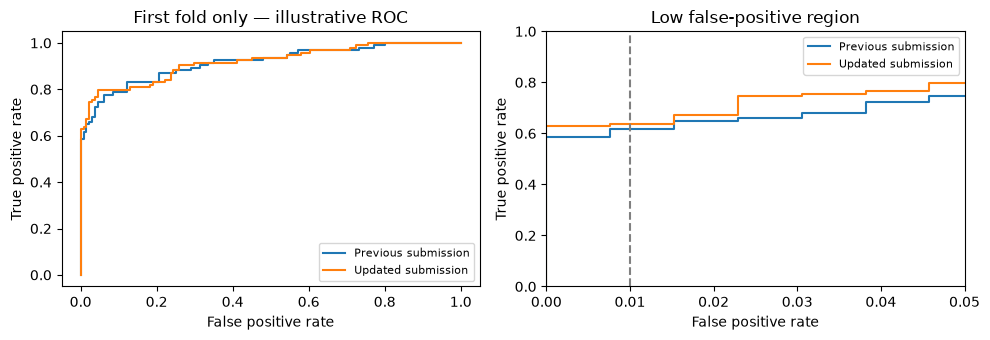

In [6]:
FINAL_SEEDS = [19, 43, 101, 521, 991, 2011, 4001, 7001, 12007, 19937]
seeds = FINAL_SEEDS if RUN_REPEATED_VALIDATION else [19]
quick_rows, first_roc = [], {}
for seed in seeds:
    for fold, (train, val) in enumerate(StratifiedKFold(5, shuffle=True, random_state=seed).split(X_dev, y_dev)):
        for name, function in [('Previous submission', original_predict), ('Updated submission', predictTest)]:
            scores = function(X_dev[train], y_dev[train], X_dev[val])
            quick_rows.append({'model': name, 'seed': seed, 'fold': fold, **metrics(y_dev[val], scores)})
            if seed == seeds[0] and fold == 0:
                first_roc[name] = roc_curve(y_dev[val], scores)[:2]
quick_results = pd.DataFrame(quick_rows)
display(quick_results.groupby('model')[['auc', 'tpr', 'pauc']].agg(['mean', 'std']).round(5))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for name, (fpr, tpr) in first_roc.items():
    for ax in axes: ax.plot(fpr, tpr, label=name)
for ax in axes:
    ax.set(xlabel='False positive rate', ylabel='True positive rate')
    ax.legend(fontsize=8)
axes[0].set_title('First fold only — illustrative ROC')
axes[1].set(xlim=(0, .05), ylim=(0, 1), title='Low false-positive region')
axes[1].axvline(.01, color='gray', linestyle='--')
plt.tight_layout()
plt.show()

## 4. Recorded results from the extended run — October 25, 2026

These compact records are measured results from the completed local run, not fresh
cell executions. They refer to the original CSV fingerprint. All paired comparisons
used the same rows for both classifiers. Confirmation and follow-up splits informed
selection; the final 50-fold comparison was run after freezing the replacement recipe.
It still reuses development emails and is not an independent final test.

Do not average the rows as if they were independent experiments. The prior 375-email
audit was not reopened for tuning or used to claim a new-model audit score.

In [7]:
RECORDED_COMPARISONS = [{'protocol': 'confirm', 'folds_or_partitions': 15, 'model': 'Previous submission', 'auc': 0.9210812360092078, 'tpr': 0.5272732285635511}, {'protocol': 'confirm', 'folds_or_partitions': 15, 'model': 'Updated submission', 'auc': 0.9251499977739482, 'tpr': 0.5491452991452992}, {'protocol': 'verification', 'folds_or_partitions': 12, 'model': 'Previous submission', 'auc': 0.9182763192274903, 'tpr': 0.5375206782464848}, {'protocol': 'verification', 'folds_or_partitions': 12, 'model': 'Updated submission', 'auc': 0.9211167792453697, 'tpr': 0.5557795698924731}, {'protocol': 'final_comparison', 'folds_or_partitions': 50, 'model': 'Previous submission', 'auc': 0.9221003556710096, 'tpr': 0.5522077327842598}, {'protocol': 'final_comparison', 'folds_or_partitions': 50, 'model': 'Updated submission', 'auc': 0.9239492662218174, 'tpr': 0.5786158773735987}, {'protocol': '50 stratified 80/20 holdouts', 'folds_or_partitions': 50, 'model': 'Previous submission', 'auc': 0.9251547735418703, 'tpr': 0.5516129032258064}, {'protocol': '50 stratified 80/20 holdouts', 'folds_or_partitions': 50, 'model': 'Updated submission', 'auc': 0.9254040404040406, 'tpr': 0.5733333333333333}]
display(pd.DataFrame(RECORDED_COMPARISONS).round(5))

,protocol,folds_or_partitions,model,auc,tpr
0,confirm,15,Previous submission,0.92108,0.52727
1,confirm,15,Updated submission,0.92515,0.54915
2,verification,12,Previous submission,0.91828,0.53752
3,verification,12,Updated submission,0.92112,0.55578
4,final_comparison,50,Previous submission,0.92210,0.55221
5,final_comparison,50,Updated submission,0.92395,0.57862
6,50 stratified 80/20 holdouts,50,Previous submission,0.92515,0.55161
7,50 stratified 80/20 holdouts,50,Updated submission,0.92540,0.57333


### Negative findings and robustness

KNN-imputed logistic regression looked excellent on the initial screen, but its TPR
fell below the old submission on broader validation. An all-logistic blend also lost
its advantage in the 50-holdout check, so it was rejected. Several high-AUC blends
sacrificed low-FPR detection. The retained weights are simple (0.50/0.25/0.25), despite
searching thousands of more precise alternatives.

In the nested diagnostic, every outer training fold repeated the whole model and
ensemble search before scoring its outer validation fold. This exposed unstable
selection. The original classifier and search library had already been developed on
these emails, so this diagnostic also has historical data-reuse limitations. It is
not a pristine unbiased evaluation of the entire project.

The missingness plot hides an additional fraction of observed values in the same ten
validation partitions, preserving the real labels. It tests robustness to data loss;
it does not create independent labeled emails or prove behavior under other shifts.

,auc,tpr
original,0.91618,0.52776
best_single,0.91135,0.49238
balanced_selection,0.91402,0.48803
auc_selection,0.91507,0.51487


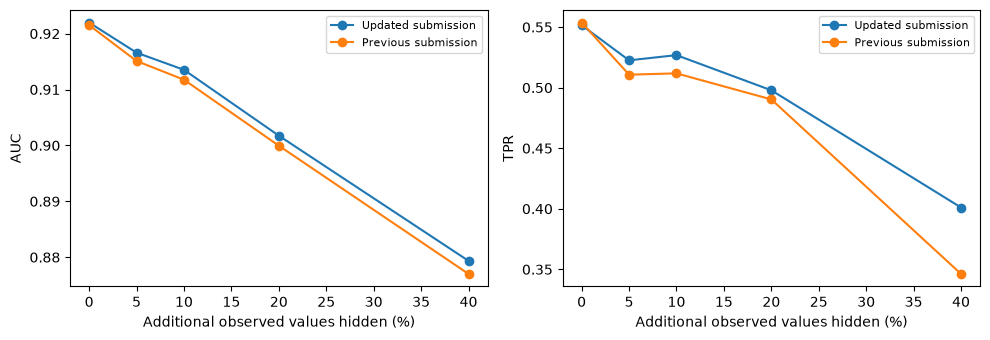

In [8]:
NESTED_RECORDED = {'original': {'auc': 0.9161837009981065, 'tpr': 0.5277639922801213, 'pauc': 0.705027905841963}, 'best_single': {'auc': 0.911354108118359, 'tpr': 0.49237661979597463, 'pauc': 0.6953457469360006}, 'balanced_selection': {'auc': 0.9140152885689782, 'tpr': 0.4880272952853597, 'pauc': 0.6968433462270301}, 'auc_selection': {'auc': 0.9150739993382503, 'tpr': 0.5148745519713261, 'pauc': 0.69486623036076}}
display(pd.DataFrame(NESTED_RECORDED).T[['auc', 'tpr']].round(5))
STRESS_RECORDED = [{'additional_missing': 0.0, 'name': 'blend_1', 'auc': 0.9219778429455848, 'tpr': 0.5516129032258064}, {'additional_missing': 0.0, 'name': 'original', 'auc': 0.921513522319974, 'tpr': 0.553763440860215}, {'additional_missing': 0.05, 'name': 'blend_1', 'auc': 0.9165933528836755, 'tpr': 0.5225806451612903}, {'additional_missing': 0.05, 'name': 'original', 'auc': 0.9151026392961876, 'tpr': 0.510752688172043}, {'additional_missing': 0.1, 'name': 'blend_1', 'auc': 0.9135223199739329, 'tpr': 0.5268817204301075}, {'additional_missing': 0.1, 'name': 'original', 'auc': 0.9117546432062561, 'tpr': 0.5118279569892473}, {'additional_missing': 0.2, 'name': 'blend_1', 'auc': 0.9017432388400131, 'tpr': 0.4978494623655914}, {'additional_missing': 0.2, 'name': 'original', 'auc': 0.8999511241446726, 'tpr': 0.4903225806451613}, {'additional_missing': 0.4, 'name': 'blend_1', 'auc': 0.8793499511241446, 'tpr': 0.4010752688172043}, {'additional_missing': 0.4, 'name': 'original', 'auc': 0.8770120560443141, 'tpr': 0.3462365591397849}]

stress_frame = pd.DataFrame(STRESS_RECORDED)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for name, group in stress_frame.groupby('name'):
    label = 'Updated submission' if name == 'blend_1' else 'Previous submission'
    for ax, metric in zip(axes, ['auc', 'tpr']):
        ax.plot(group.additional_missing * 100, group[metric], marker='o', label=label)
        ax.set(xlabel='Additional observed values hidden (%)', ylabel=metric.upper())
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Model implementations for further exploration

These readable definitions support the full search. They include course models
(Perceptron, Adaline, logistic regression, SVM, decision trees, KNN, ensembles,
PCA/LDA, feature selection, and a small neural network), plus alternative binning,
splines, interactions, kernels, and imputation strategies.

No XGBoost, LightGBM, or CatBoost claim is made: those packages were unavailable and
were not part of this run. This is an extensive finite sklearn search, not exhaustion
of every possible classifier or hyperparameter.

In [9]:
class FrequencyBinner(TransformerMixin, BaseEstimator):
    """Keep absence separate from positive-frequency bins; learn bins on train only.

    Missing entries become training-set category proportions, not zero/absence.
    """
    def __init__(self, bins=3, presence=False):
        self.bins = bins
        self.presence = presence

    def fit(self, x, y=None):
        x = np.asarray(x, dtype=float)
        self.edges_ = []
        self.priors_ = []
        for column in x.T:
            observed = column[np.isfinite(column) & (column >= 0)]
            positive = observed[observed > 0]
            edges = np.unique(np.quantile(positive, np.arange(1, self.bins) / self.bins)) if len(positive) else np.array([])
            codes = np.where(observed > 0, 1 + np.searchsorted(edges, observed, side="right"), 0)
            counts = np.bincount(codes, minlength=len(edges) + 2).astype(float)
            self.edges_.append(edges)
            self.priors_.append(counts / counts.sum() if counts.sum() else np.r_[1., np.zeros(len(edges) + 1)])
        return self

    def transform(self, x):
        pieces = []
        for column, edges, prior in zip(np.asarray(x, dtype=float).T, self.edges_, self.priors_):
            missing = ~np.isfinite(column) | (column < 0)
            codes = np.where(column > 0, 1 + np.searchsorted(edges, column, side="right"), 0)
            encoded = np.eye(len(prior))[codes]
            encoded[missing] = prior
            if self.presence:
                encoded = np.column_stack((1.0 - encoded[:, 0], encoded))
            pieces.append(encoded)
        return np.hstack(pieces)

def missing_to_nan(x):
    x = np.asarray(x, dtype=float).copy()
    x[x == -1] = np.nan
    return x

def word_transform(x, kind="raw", scale=1000.0):
    if kind == "raw":
        return x
    if kind == "log":
        return np.log1p(scale * x)
    if kind == "sqrt":
        return np.sqrt(x)
    if kind == "binary":
        return np.where(np.isnan(x), np.nan, (x > 0).astype(float))
    if kind == "log_binary":
        return np.hstack((np.log1p(scale * x),
            np.where(np.isnan(x), np.nan, (x > 0).astype(float))))
    raise ValueError(kind)

In [10]:
def make_model(config):
    c = dict(config)
    family = c.pop("family")
    transform = c.pop("transform", "raw")
    scale = c.pop("scale", 1000.0)
    impute = c.pop("impute", "median")
    indicators = c.pop("indicators", False)
    standardize = c.pop("standardize", True)
    bins = c.pop("bins", 3)
    presence = c.pop("presence", False)
    steps = [("missing", FunctionTransformer(missing_to_nan)),
             ("transform", FunctionTransformer(word_transform,
                kw_args={"kind": transform, "scale": scale}))]
    if impute != "native":
        steps.append(("imputer", SimpleImputer(strategy=impute,
                     add_indicator=indicators, keep_empty_features=True)))
    if family == "binned":
        steps = [("frequency_bins", FrequencyBinner(bins=bins, presence=presence))]
    if family in ("svm", "logistic", "binned") and standardize:
        steps.append(("scaler", StandardScaler()))
    if family == "baseline":
        estimator = GaussianNB(**c)
    elif family == "bernoulli":
        estimator = BernoulliNB(**c)
    elif family in ("logistic", "binned"):
        estimator = LogisticRegression(max_iter=3000, random_state=MODEL_SEED, **c)
    elif family == "svm":
        estimator = SVC(kernel="rbf", probability=True, cache_size=256,
                        random_state=MODEL_SEED, **c)
    elif family == "gb":
        estimator = GradientBoostingClassifier(random_state=MODEL_SEED, **c)
    elif family == "hist":
        estimator = HistGradientBoostingClassifier(early_stopping=False,
                    random_state=MODEL_SEED, **c)
    elif family == "extra":
        estimator = ExtraTreesClassifier(n_jobs=2, random_state=MODEL_SEED, **c)
    elif family == "forest":
        estimator = RandomForestClassifier(n_jobs=2, random_state=MODEL_SEED, **c)
    else:
        raise ValueError(family)
    return Pipeline(steps + [("model", estimator)])

In [11]:
class AdalineSGD(ClassifierMixin, BaseEstimator):
    """Adaline-style linear squared-error classifier with averaged SGD.

    Encode ham/spam as -1/+1, fit a linear output with squared-error loss, and
    use that continuous output to rank emails. L2 regularization and averaging
    are practical extensions to textbook Adaline. This is not a probability model.
    """
    def __init__(self, alpha=0.0001, eta0=0.001):
        self.alpha = alpha
        self.eta0 = eta0

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.model_ = SGDRegressor(loss="squared_error", penalty="l2", alpha=self.alpha,
            learning_rate="invscaling", eta0=self.eta0, average=True,
            max_iter=3000, tol=1e-5, random_state=MODEL_SEED)
        self.model_.fit(X, 2 * np.asarray(y) - 1)
        return self

    def decision_function(self, X):
        return self.model_.predict(X)

    def predict(self, X):
        return (self.decision_function(X) >= 0).astype(int)

In [12]:
def make_course_model(config):
    c = dict(config)
    if c["family"] in {"baseline", "logistic", "binned", "svm", "gb", "hist", "extra", "forest", "bernoulli"}:
        return make_model(c)
    family = c.pop("family")
    transform = c.pop("transform", "log_binary")
    impute = c.pop("impute", "mean")
    indicators = c.pop("indicators", False)
    standardize = c.pop("standardize", family not in {"tree", "adaboost"})
    components = c.pop("components", None)
    selected_features = c.pop("selected_features", None)
    steps = [("missing", FunctionTransformer(missing_to_nan)),
             ("transform", FunctionTransformer(word_transform, kw_args={"kind": transform})),
             ("imputer", SimpleImputer(strategy=impute, add_indicator=indicators,
                                        keep_empty_features=True))]
    if standardize:
        steps.append(("scaler", StandardScaler()))
    if selected_features is not None:
        steps.append(("feature_selection", SelectKBest(f_classif, k=selected_features)))
    if components is not None:
        steps.append(("pca", PCA(n_components=components, svd_solver="full")))
    if family == "perceptron":
        estimator = Perceptron(penalty="l2", max_iter=3000, tol=1e-4,
                               random_state=MODEL_SEED, **c)
    elif family == "adaline":
        estimator = AdalineSGD(**c)
    elif family == "linear_svm":
        estimator = LinearSVC(dual=False, max_iter=10000, random_state=MODEL_SEED, **c)
    elif family == "tree":
        estimator = DecisionTreeClassifier(random_state=MODEL_SEED, **c)
    elif family == "knn":
        estimator = KNeighborsClassifier(n_jobs=2, **c)
    elif family == "adaboost":
        depth = c.pop("depth")
        base_tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=5, random_state=MODEL_SEED)
        estimator = AdaBoostClassifier(estimator=base_tree, random_state=MODEL_SEED, **c)
    elif family == "lda":
        estimator = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto", **c)
    elif family == "lda_projection":
        # With two classes LDA offers at most one discriminant direction.
        steps.append(("lda", LinearDiscriminantAnalysis(solver="svd", n_components=1)))
        estimator = LogisticRegression(max_iter=3000, **c)
    elif family in {"pca_logistic", "selected_logistic"}:
        estimator = LogisticRegression(max_iter=3000, random_state=MODEL_SEED, **c)
    elif family == "pca_svm":
        estimator = SVC(kernel="rbf", probability=True, random_state=MODEL_SEED, **c)
    elif family == "mlp":
        c.setdefault("max_iter", 1500)
        c.setdefault("max_fun", 25000)
        estimator = MLPClassifier(solver="lbfgs", random_state=MODEL_SEED, **c)
    else:
        raise ValueError(family)
    return Pipeline(steps + [("model", estimator)])

In [13]:
class AdvancedBinner(TransformerMixin, BaseEstimator):
    def __init__(self,bins=5,spacing='quantile',presence=False,missing='prior',smooth=0.):
        self.bins=bins; self.spacing=spacing; self.presence=presence
        self.missing=missing; self.smooth=smooth
    def fit(self,X,y=None):
        self.edges_=[]; self.priors_=[]
        for col in np.asarray(X).T:
            obs=col[np.isfinite(col)&(col>=0)]; pos=obs[obs>0]
            if not len(pos):edges=np.array([])
            elif self.spacing=='quantile':edges=np.unique(np.quantile(pos,np.arange(1,self.bins)/self.bins))
            else:edges=np.unique(np.expm1(np.linspace(np.log1p(1000*pos.min()),np.log1p(1000*pos.max()),self.bins+1)[1:-1])/1000)
            codes=np.where(obs>0,1+np.searchsorted(edges,obs,side='right'),0)
            counts=np.bincount(codes,minlength=len(edges)+2).astype(float)+self.smooth
            prior=counts/counts.sum() if counts.sum() else np.r_[1.,np.zeros(len(edges)+1)]
            self.edges_.append(edges);self.priors_.append(prior)
        return self
    def transform(self,X):
        blocks=[]
        for col,edges,prior in zip(np.asarray(X).T,self.edges_,self.priors_):
            miss=~np.isfinite(col)|(col<0)
            codes=np.where(col>0,1+np.searchsorted(edges,col,side='right'),0)
            encoded=np.eye(len(prior))[codes]
            encoded[miss]=prior if self.missing in ('prior','indicator') else 0.
            if self.presence:encoded=np.c_[1-encoded[:,0],encoded]
            if self.missing=='indicator':encoded=np.c_[encoded,miss.astype(float)]
            blocks.append(encoded)
        return np.hstack(blocks)

class PowerPresence(TransformerMixin,BaseEstimator):
    def __init__(self,power=.5):self.power=power
    def fit(self,X,y=None):return self
    def transform(self,X):
        X=missing_to_nan(X)
        return np.c_[np.power(X,self.power),np.where(np.isnan(X),np.nan,(X>0).astype(float))]

class KernelSVC(ClassifierMixin,BaseEstimator):
    def __init__(self,kernel='laplacian',C=1.,gamma=.01):self.kernel=kernel;self.C=C;self.gamma=gamma
    def _kernel(self,X,Y):
        return (laplacian_kernel if self.kernel=='laplacian' else chi2_kernel)(X,Y,gamma=self.gamma)
    def fit(self,X,y):
        self.train_=np.asarray(X).copy();self.classes_=np.unique(y)
        self.model_=SVC(kernel='precomputed',C=self.C,probability=True,random_state=MODEL_SEED)
        self.model_.fit(self._kernel(self.train_,self.train_),y)
        return self
    def predict_proba(self,X):return self.model_.predict_proba(self._kernel(X,self.train_))

class PresenceWeight(TransformerMixin,BaseEstimator):
    def __init__(self,weight=1.):self.weight=weight
    def fit(self,X,y=None):return self
    def transform(self,X):
        X=np.asarray(X).copy();X[:,X.shape[1]//2:]*=self.weight;return X

In [14]:
def build(config):
    c=dict(config);family=c.pop('family')
    if family in ('knn_binned','knn_hist','knn_svm'):
        kind=c.pop('transform','log');neighbors=c.pop('neighbors',15)
        weights=c.pop('weights','uniform');indicators=c.pop('indicators',False)
        steps=[('missing',FunctionTransformer(missing_to_nan)),
               ('features',FunctionTransformer(word_transform,kw_args={'kind':kind})),
               ('impute',KNNImputer(n_neighbors=neighbors,weights=weights,add_indicator=indicators,keep_empty_features=True))]
        if family=='knn_binned':
            C=c.pop('C');steps.append(('bins',AdvancedBinner(bins=c.pop('bins',5),presence=c.pop('presence',False))))
            estimator=LogisticRegression(C=C,max_iter=3000,**c)
        elif family=='knn_hist':estimator=HistGradientBoostingClassifier(early_stopping=False,random_state=MODEL_SEED,**c)
        else:
            steps.append(('scale',StandardScaler()));estimator=SVC(probability=True,random_state=MODEL_SEED,**c)
        return Pipeline(steps+[('model',estimator)])
    if family=='advanced_bins':
        C=c.pop('C');standardize=c.pop('standardize',False);weight=c.pop('ham_weight',1.)
        steps=[('bins',AdvancedBinner(**c))]
        if standardize:steps.append(('scale',StandardScaler()))
        return Pipeline(steps+[('model',LogisticRegression(C=C,max_iter=3000,class_weight={0:weight,1:1.}))])
    if family in ('spline','interactions','power','knn_logistic','iterative_logistic','chi2_logistic','kernel_svm'):
        C=c.pop('C');kind=c.pop('transform','log_binary');impute=c.pop('impute','mean')
        scale=c.pop('scale',1000.);indicators=c.pop('indicators',False)
        steps=[('missing',FunctionTransformer(missing_to_nan)),('features',FunctionTransformer(word_transform,kw_args={'kind':kind,'scale':scale}))]
        if family=='power':steps=[('features',PowerPresence(c.pop('power')))]
        if family=='knn_logistic':
            presence_weight=c.pop('presence_weight',1.);pre_scale=c.pop('pre_scale',False)
            if presence_weight!=1.:steps.append(('presence_weight',PresenceWeight(presence_weight)))
            if pre_scale:steps.append(('pre_scale',StandardScaler()))
            steps.append(('impute',KNNImputer(n_neighbors=c.pop('neighbors'),weights=c.pop('weights','distance'),add_indicator=indicators,keep_empty_features=True)))
        elif family=='iterative_logistic':
            mode=c.pop('estimator','bayesian');max_iter=c.pop('impute_iter',10)
            estimator=BayesianRidge() if mode=='bayesian' else ExtraTreesRegressor(n_estimators=30,max_depth=5,min_samples_leaf=5,n_jobs=1,random_state=MODEL_SEED)
            steps.append(('impute',IterativeImputer(estimator=estimator,max_iter=max_iter,initial_strategy='mean',min_value=0,add_indicator=indicators,random_state=MODEL_SEED,keep_empty_features=True,n_nearest_features=c.pop('nearest_features',None))))
        else:steps.append(('impute',SimpleImputer(strategy=impute,add_indicator=indicators,keep_empty_features=True)))
        if family=='spline':steps.append(('spline',SplineTransformer(n_knots=c.pop('knots'),degree=c.pop('degree'),include_bias=False,knots='quantile',extrapolation='constant')))
        if family=='interactions':
            selected=c.pop('features',30)
            steps += [('select',SelectKBest(f_classif,k=selected)),('poly',PolynomialFeatures(degree=2,interaction_only=c.pop('interaction_only',True),include_bias=False))]
        if family=='chi2_logistic':steps.append(('chi2',AdditiveChi2Sampler(sample_steps=c.pop('steps',2))))
        if family=='kernel_svm':
            kernel=c.pop('kernel');gamma=c.pop('gamma')
            if kernel=='laplacian':steps.append(('scale',StandardScaler()))
            return Pipeline(steps+[('model',KernelSVC(C=C,kernel=kernel,gamma=gamma))])
        steps.append(('scale',StandardScaler()))
        return Pipeline(steps+[('model',LogisticRegression(C=C,max_iter=3000,**c))])
    ham_weight=c.pop('ham_weight',None)
    model=make_course_model({'family':family,**c})
    if family in ('forest','extra'):model.set_params(model__n_jobs=1)
    if ham_weight is not None and family in ('logistic','hist','svm','forest','extra'):
        model.set_params(model__class_weight={0:ham_weight,1:1.})
    return model

## 6. Exact finite parameter library

Each dictionary below is a compact Cartesian grid. Singleton lists fix parameters;
longer lists enumerate alternatives. Combining these grids reproduces the exact
**1,841 serialized configurations** screened in the extended run. A few configurations
express identical defaults differently; the count is configurations, not distinct
mathematical models. All random estimators use seed 340.

Do not change a split seed to improve a displayed score. If you alter the search,
declare the comparison protocol first and evaluate the resulting procedure on fresh
data when it becomes available.

In [15]:
MODEL_GRIDS = [
    {'C': [0.03, 0.1, 0.3, 1.0], 'bins': [3, 5, 8], 'family': ['binned'], 'presence': [True], 'standardize': [False]},
    {'family': ['baseline'], 'impute': ['mean']},
    {'family': ['original']},
    {'C': [0.01, 0.1, 1.0, 10.0], 'family': ['logistic'], 'impute': ['mean'], 'standardize': [False, True], 'transform': ['binary', 'log', 'log_binary']},
    {'family': ['hist'], 'impute': ['median', 'native'], 'l2_regularization': [1.0], 'learning_rate': [0.05], 'max_iter': [250], 'max_leaf_nodes': [15, 7], 'min_samples_leaf': [15]},
    {'family': ['hist'], 'impute': ['native'], 'l2_regularization': [1.0, 10.0], 'learning_rate': [0.05], 'max_iter': [150, 400], 'max_leaf_nodes': [15, 3, 7], 'min_samples_leaf': [20]},
    {'family': ['hist'], 'impute': ['native'], 'l2_regularization': [0.1, 1.0, 10.0, 100.0], 'learning_rate': [0.05], 'max_iter': [150, 400], 'max_leaf_nodes': [15, 3, 31, 7], 'min_samples_leaf': [10, 30]},
    {'C': [0.3, 10.0, 3.0, 30.0], 'family': ['svm'], 'gamma': [0.01], 'impute': ['mean'], 'standardize': [False], 'transform': ['binary']},
    {'C': [0.3, 1.0, 10.0, 100.0, 3.0, 30.0], 'family': ['svm'], 'gamma': [0.001, 0.003, 0.01, 0.03, 0.1], 'impute': ['mean'], 'standardize': [True], 'transform': ['binary', 'log', 'log_binary']},
    {'C': [10.0, 3.0, 30.0], 'family': ['svm'], 'gamma': [0.03, 0.1], 'impute': ['mean'], 'standardize': [False], 'transform': ['binary']},
    {'C': [10.0, 3.0, 30.0], 'family': ['svm'], 'gamma': [0.01, 0.03, 0.1], 'impute': ['mean'], 'standardize': [False], 'transform': ['log_binary']},
    {'C': [0.3, 3.0, 30.0], 'family': ['svm'], 'gamma': [0.001, 0.01], 'impute': ['mean'], 'standardize': [False], 'transform': ['log']},
    {'C': [0.3, 3.0, 30.0], 'family': ['svm'], 'gamma': [0.001], 'impute': ['mean'], 'standardize': [False], 'transform': ['binary']},
    {'family': ['gb'], 'impute': ['mean', 'median'], 'indicators': [False, True], 'learning_rate': [0.05], 'max_depth': [2], 'min_samples_leaf': [8], 'n_estimators': [300]},
    {'family': ['gb'], 'impute': ['mean', 'median'], 'indicators': [False, True], 'learning_rate': [0.03, 0.1], 'max_depth': [1, 2, 3], 'min_samples_leaf': [10], 'n_estimators': [150, 500]},
    {'C': [0.03, 0.3, 3.0], 'bins': [2, 3, 5], 'family': ['binned'], 'standardize': [False, True]},
    {'alpha': [0.0001, 0.01], 'family': ['perceptron'], 'transform': ['binary', 'log', 'log_binary']},
    {'C': [0.01, 0.1, 1.0, 10.0], 'family': ['linear_svm'], 'transform': ['binary', 'log_binary']},
    {'C': [1.0], 'family': ['lda_projection'], 'transform': ['log', 'log_binary']},
    {'C': [0.003, 0.01, 0.03, 0.1, 0.3, 1.0], 'family': ['chi2_logistic'], 'transform': ['binary', 'log', 'log_binary']},
    {'family': ['tree'], 'impute': ['median'], 'indicators': [True], 'max_depth': [2, 4, 6, None], 'min_samples_leaf': [15, 5], 'transform': ['raw']},
    {'alpha': [0.0001, 0.01], 'eta0': [0.001], 'family': ['adaline'], 'transform': ['binary', 'log', 'log_binary']},
    {'family': ['knn'], 'n_neighbors': [15, 31, 5], 'p': [1, 2], 'transform': ['binary', 'log'], 'weights': ['distance', 'uniform']},
    {'family': ['extra', 'forest'], 'impute': ['mean'], 'max_features': [0.7], 'min_samples_leaf': [2], 'n_estimators': [400], 'transform': ['log', 'raw']},
    {'family': ['lda'], 'transform': ['binary', 'log', 'log_binary', 'raw']},
    {'C': [3.0], 'components': [0.95, 10, 20], 'family': ['pca_svm'], 'gamma': [0.01], 'transform': ['log']},
    {'C': [0.01], 'components': [0.95, 10, 20], 'family': ['pca_logistic'], 'transform': ['log_binary']},
    {'C': [0.01], 'family': ['selected_logistic'], 'selected_features': [10, 20, 40], 'transform': ['log_binary']},
    {'depth': [1, 2], 'family': ['adaboost'], 'learning_rate': [0.1, 1.0], 'n_estimators': [100, 300], 'transform': ['raw']},
    {'family': ['gb'], 'impute': ['mean'], 'learning_rate': [0.05], 'max_depth': [1, 2, 3], 'min_samples_leaf': [10], 'n_estimators': [100, 600]},
    {'alpha': [1.0, 10.0], 'family': ['mlp'], 'hidden_layer_sizes': [[16]], 'transform': ['binary', 'log_binary']},
    {'C': [0.03, 0.1, 0.3], 'family': ['logistic'], 'impute': ['mean'], 'indicators': [True], 'transform': ['binary', 'log_binary']},
    {'C': [1.0], 'family': ['logistic'], 'impute': ['mean'], 'transform': ['binary', 'log', 'raw']},
    {'C': [3.0], 'family': ['svm'], 'gamma': ['scale'], 'impute': ['mean', 'median'], 'transform': ['log', 'raw', 'sqrt']},
    {'C': [3.0], 'family': ['svm'], 'gamma': ['scale'], 'impute': ['mean'], 'indicators': [True], 'transform': ['log']},
    {'alpha': [1.0], 'family': ['bernoulli'], 'impute': ['median'], 'transform': ['binary']},
    {'C': [0.01, 0.03, 0.1, 0.3, 1, 3], 'bins': [12, 2, 3, 5, 8], 'family': ['advanced_bins'], 'missing': ['indicator', 'prior'], 'presence': [False, True], 'spacing': ['log', 'quantile']},
    {'C': [0.03, 0.1, 0.3, 1], 'bins': [3, 5, 8], 'family': ['advanced_bins'], 'missing': ['prior'], 'presence': [True], 'smooth': [0.5, 10.0, 2.0], 'spacing': ['quantile']},
    {'C': [0.003, 0.01, 0.03, 0.1, 0.3, 1.0], 'family': ['logistic'], 'impute': ['mean', 'median'], 'indicators': [False, True], 'scale': [10.0, 100.0, 1000.0, 10000.0], 'transform': ['log_binary']},
    {'C': [0.003, 0.01, 0.03, 0.1, 0.3, 1.0], 'family': ['power'], 'power': [0.1, 0.25, 0.5, 0.75, 1.0]},
    {'C': [0.003, 0.03, 0.3, 3.0], 'degree': [1, 2, 3], 'family': ['spline'], 'indicators': [False, True], 'knots': [3, 5, 8], 'transform': ['log']},
    {'C': [0.001, 0.003, 0.01, 0.03, 0.1], 'family': ['interactions'], 'features': [15, 30, 60], 'interaction_only': [False, True]},
    {'C': [0.003, 0.01, 0.03, 0.1], 'family': ['knn_logistic'], 'neighbors': [15, 3, 31, 7], 'weights': ['distance', 'uniform']},
    {'C': [1.0, 10.0, 3.0, 30.0], 'family': ['kernel_svm'], 'gamma': [0.003, 0.01, 0.03, 0.1], 'kernel': ['laplacian'], 'transform': ['binary', 'log']},
    {'C': [0.1, 1.0, 10.0, 100.0], 'family': ['kernel_svm'], 'gamma': [0.01, 0.1, 1.0], 'kernel': ['chi2'], 'transform': ['binary', 'log']},
    {'family': ['extra', 'forest'], 'impute': ['mean'], 'max_features': [0.3, 0.7, 1.0], 'min_samples_leaf': [1, 10, 2, 5], 'n_estimators': [300]},
    {'alpha': [0.1, 1.0, 10.0, 100.0], 'family': ['mlp'], 'hidden_layer_sizes': [[16], [32, 16], [32], [8]], 'max_fun': [50000], 'max_iter': [3000], 'transform': ['binary', 'log_binary']},
    {'C': [0.01, 0.1, 0.3, 1.0], 'family': ['logistic'], 'ham_weight': [0.25, 0.5, 2.0, 4.0], 'impute': ['mean'], 'transform': ['log_binary']},
    {'C': [0.01, 0.1, 0.3, 1.0], 'bins': [5], 'family': ['advanced_bins'], 'ham_weight': [0.25, 0.5, 2.0, 4.0], 'presence': [True]},
    {'C': [0.003, 0.01, 0.03, 0.1, 0.3], 'family': ['knn_logistic'], 'indicators': [False, True], 'neighbors': [1, 15, 3, 31, 63, 7], 'pre_scale': [False, True], 'transform': ['log', 'log_binary'], 'weights': ['distance', 'uniform']},
    {'C': [0.01, 0.03, 0.1], 'family': ['knn_logistic'], 'neighbors': [15, 3, 31], 'presence_weight': [0.25, 2.0, 5.0], 'scale': [100.0, 1000.0, 10000.0], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.003, 0.01, 0.03, 0.1, 0.3], 'estimator': ['bayesian', 'trees'], 'family': ['iterative_logistic'], 'impute_iter': [5], 'indicators': [False, True], 'nearest_features': [15], 'transform': ['log', 'log_binary']},
    {'C': [0.03, 0.1, 0.3, 1.0], 'family': ['knn_binned'], 'indicators': [False, True], 'neighbors': [15, 3, 31, 7], 'presence': [False, True]},
    {'family': ['knn_hist'], 'l2_regularization': [0.1, 1.0, 10.0], 'learning_rate': [0.05], 'max_iter': [250], 'max_leaf_nodes': [15, 3, 7], 'min_samples_leaf': [15], 'neighbors': [31, 7]},
    {'C': [1.0, 10.0, 3.0, 30.0], 'family': ['knn_svm'], 'gamma': [0.003, 0.01, 0.03], 'neighbors': [31, 7], 'transform': ['log', 'log_binary']},
]

FULL_LIBRARY = list(ParameterGrid(MODEL_GRIDS))
assert len(FULL_LIBRARY) == 1841
assert len({identity(c) for c in FULL_LIBRARY}) == 1841
display(pd.Series([c['family'] for c in FULL_LIBRARY]).value_counts().rename('configurations').to_frame())

,configurations
knn_logistic,593
advanced_bins,292
logistic,145
svm,125
hist,80
spline,72
knn_binned,64
gb,58
kernel_svm,56
knn_svm,48


In [16]:
CONFIRMATION_GRIDS = [
    {'family': ['original']},
    {'C': [0.01], 'family': ['selected_logistic'], 'selected_features': [40], 'transform': ['log_binary']},
    {'family': ['knn'], 'n_neighbors': [31], 'p': [2], 'transform': ['log'], 'weights': ['distance']},
    {'family': ['knn'], 'n_neighbors': [15], 'p': [1], 'transform': ['log'], 'weights': ['distance']},
    {'family': ['hist'], 'impute': ['median'], 'l2_regularization': [1.0], 'learning_rate': [0.05], 'max_iter': [250], 'max_leaf_nodes': [7], 'min_samples_leaf': [15]},
    {'family': ['hist'], 'impute': ['native'], 'l2_regularization': [0.1], 'learning_rate': [0.05], 'max_iter': [400], 'max_leaf_nodes': [3], 'min_samples_leaf': [10]},
    {'family': ['hist'], 'impute': ['native'], 'l2_regularization': [1.0], 'learning_rate': [0.05], 'max_iter': [150], 'max_leaf_nodes': [3], 'min_samples_leaf': [30]},
    {'family': ['baseline'], 'impute': ['mean']},
    {'C': [0.01, 0.03, 0.1, 0.3], 'family': ['knn_logistic'], 'indicators': [False], 'neighbors': [7], 'pre_scale': [True], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.03], 'family': ['knn_logistic'], 'indicators': [True], 'neighbors': [7], 'pre_scale': [True], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.003, 0.03, 0.1], 'family': ['knn_logistic'], 'indicators': [False], 'neighbors': [15, 31, 63], 'pre_scale': [False], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.01, 0.03, 0.1], 'family': ['knn_logistic'], 'indicators': [False], 'neighbors': [31], 'pre_scale': [True], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.003, 0.01, 0.03, 0.1], 'family': ['knn_logistic'], 'indicators': [False], 'neighbors': [15], 'pre_scale': [True], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.03], 'family': ['knn_logistic'], 'indicators': [False], 'neighbors': [63], 'pre_scale': [True], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.01, 0.03], 'family': ['knn_logistic'], 'indicators': [False], 'neighbors': [3], 'pre_scale': [False, True], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.03], 'family': ['knn_logistic'], 'indicators': [False], 'neighbors': [3, 31, 63], 'pre_scale': [False], 'transform': ['log_binary'], 'weights': ['distance']},
    {'C': [0.01, 0.03, 0.1], 'family': ['knn_logistic'], 'indicators': [False], 'neighbors': [15], 'pre_scale': [False], 'transform': ['log_binary'], 'weights': ['distance']},
    {'C': [0.01], 'family': ['knn_logistic'], 'indicators': [False], 'neighbors': [15], 'pre_scale': [True], 'transform': ['log_binary'], 'weights': ['distance']},
    {'C': [0.01], 'family': ['knn_logistic'], 'indicators': [False], 'neighbors': [7], 'pre_scale': [False], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.01], 'family': ['knn_logistic'], 'neighbors': [3], 'presence_weight': [0.25], 'scale': [100.0], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.01, 0.03, 0.1], 'family': ['knn_logistic'], 'neighbors': [15], 'presence_weight': [2.0], 'scale': [10000.0], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.01, 0.03, 0.1], 'family': ['knn_logistic'], 'neighbors': [15, 31], 'presence_weight': [0.25], 'scale': [1000.0], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.01, 0.03, 0.1], 'family': ['knn_logistic'], 'neighbors': [31], 'presence_weight': [0.25], 'scale': [10000.0], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.03, 0.1], 'family': ['knn_logistic'], 'neighbors': [15], 'presence_weight': [0.25], 'scale': [10000.0], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.03, 0.1], 'family': ['knn_logistic'], 'neighbors': [15, 31], 'presence_weight': [5.0], 'scale': [10000.0], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.03, 0.1], 'family': ['knn_logistic'], 'neighbors': [31], 'presence_weight': [2.0], 'scale': [10000.0], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.03, 0.1], 'family': ['knn_logistic'], 'neighbors': [15, 31], 'presence_weight': [2.0, 5.0], 'scale': [1000.0], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.03], 'family': ['knn_logistic'], 'neighbors': [15], 'presence_weight': [0.25], 'scale': [100.0], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.01, 0.03], 'family': ['knn_logistic'], 'neighbors': [3], 'presence_weight': [5.0], 'scale': [1000.0], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.01, 0.03], 'family': ['knn_logistic'], 'neighbors': [15], 'presence_weight': [5.0], 'scale': [100.0], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.01], 'family': ['knn_logistic'], 'neighbors': [15], 'presence_weight': [2.0], 'scale': [100.0], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.01, 0.03], 'family': ['knn_logistic'], 'neighbors': [31], 'presence_weight': [0.25], 'scale': [100.0], 'transform': ['log_binary'], 'weights': ['uniform']},
    {'C': [0.001], 'family': ['interactions'], 'features': [60], 'interaction_only': [False, True]},
    {'C': [0.03], 'family': ['interactions'], 'features': [30], 'interaction_only': [True]},
    {'C': [0.1], 'family': ['logistic'], 'impute': ['mean'], 'indicators': [False], 'scale': [10000.0], 'transform': ['log_binary']},
    {'C': [0.003, 0.03], 'family': ['logistic'], 'impute': ['mean'], 'indicators': [False], 'scale': [1000.0], 'transform': ['log_binary']},
    {'family': ['extra', 'forest'], 'impute': ['mean'], 'max_features': [0.3], 'min_samples_leaf': [1, 10], 'n_estimators': [300]},
    {'family': ['extra'], 'impute': ['mean'], 'max_features': [0.3], 'min_samples_leaf': [5], 'n_estimators': [300]},
    {'depth': [2], 'family': ['adaboost'], 'learning_rate': [0.1], 'n_estimators': [300], 'transform': ['raw']},
    {'depth': [1], 'family': ['adaboost'], 'learning_rate': [1.0], 'n_estimators': [300], 'transform': ['raw']},
    {'C': [10.0], 'family': ['knn_svm'], 'gamma': [0.003], 'neighbors': [31], 'transform': ['log']},
    {'C': [1.0], 'family': ['knn_svm'], 'gamma': [0.003], 'neighbors': [31], 'transform': ['log_binary']},
    {'C': [3.0], 'family': ['knn_svm'], 'gamma': [0.003], 'neighbors': [7], 'transform': ['log_binary']},
    {'alpha': [0.01], 'eta0': [0.001], 'family': ['adaline'], 'transform': ['log_binary']},
    {'C': [1.0], 'family': ['lda_projection'], 'transform': ['log', 'log_binary']},
    {'C': [0.003], 'family': ['chi2_logistic'], 'transform': ['log']},
    {'C': [0.01], 'family': ['chi2_logistic', 'linear_svm'], 'transform': ['log_binary']},
    {'C': [0.3], 'bins': [12, 5], 'family': ['advanced_bins'], 'missing': ['prior'], 'presence': [True], 'spacing': ['quantile']},
    {'C': [0.3, 1], 'bins': [2], 'family': ['advanced_bins'], 'missing': ['prior'], 'presence': [True], 'spacing': ['log']},
    {'C': [0.1], 'bins': [8], 'family': ['advanced_bins'], 'missing': ['prior'], 'presence': [True], 'spacing': ['quantile']},
    {'C': [1], 'bins': [2], 'family': ['advanced_bins'], 'missing': ['prior'], 'presence': [False], 'spacing': ['log']},
    {'C': [0.3], 'bins': [5], 'family': ['advanced_bins'], 'ham_weight': [0.25, 2.0], 'presence': [True]},
    {'C': [0.3], 'bins': [8], 'family': ['advanced_bins'], 'missing': ['prior'], 'presence': [True], 'smooth': [10.0], 'spacing': ['quantile']},
    {'C': [0.1], 'bins': [8], 'family': ['advanced_bins'], 'missing': ['prior'], 'presence': [True], 'smooth': [0.5], 'spacing': ['quantile']},
    {'C': [0.3], 'bins': [5], 'family': ['advanced_bins'], 'missing': ['prior'], 'presence': [True], 'smooth': [0.5, 2.0], 'spacing': ['quantile']},
    {'C': [0.03, 0.1], 'family': ['power'], 'power': [0.25]},
    {'C': [10.0], 'family': ['kernel_svm'], 'gamma': [0.003], 'kernel': ['laplacian'], 'transform': ['log']},
    {'C': [1.0], 'family': ['kernel_svm'], 'gamma': [0.1], 'kernel': ['chi2'], 'transform': ['binary']},
    {'C': [0.1], 'family': ['kernel_svm'], 'gamma': [0.01], 'kernel': ['chi2'], 'transform': ['log']},
    {'family': ['tree'], 'impute': ['median'], 'indicators': [True], 'max_depth': [None], 'min_samples_leaf': [15], 'transform': ['raw']},
    {'family': ['tree'], 'impute': ['median'], 'indicators': [True], 'max_depth': [2], 'min_samples_leaf': [5], 'transform': ['raw']},
    {'alpha': [100.0], 'family': ['mlp'], 'hidden_layer_sizes': [[16]], 'max_fun': [50000], 'max_iter': [3000], 'transform': ['log_binary']},
    {'alpha': [10.0, 100.0], 'family': ['mlp'], 'hidden_layer_sizes': [[8]], 'max_fun': [50000], 'max_iter': [3000], 'transform': ['log_binary']},
    {'C': [0.003, 0.03], 'estimator': ['bayesian'], 'family': ['iterative_logistic'], 'impute_iter': [5], 'indicators': [False], 'nearest_features': [15], 'transform': ['log_binary']},
    {'C': [0.03], 'estimator': ['bayesian'], 'family': ['iterative_logistic'], 'impute_iter': [5], 'indicators': [True], 'nearest_features': [15], 'transform': ['log_binary']},
    {'C': [0.3], 'degree': [2], 'family': ['spline'], 'indicators': [False], 'knots': [3], 'transform': ['log']},
    {'C': [0.003], 'degree': [3], 'family': ['spline'], 'indicators': [True], 'knots': [8], 'transform': ['log']},
    {'C': [0.3], 'degree': [1], 'family': ['spline'], 'indicators': [False], 'knots': [5], 'transform': ['log']},
    {'family': ['gb'], 'impute': ['median'], 'indicators': [False], 'learning_rate': [0.03], 'max_depth': [2], 'min_samples_leaf': [10], 'n_estimators': [500]},
    {'family': ['gb'], 'impute': ['mean'], 'indicators': [True], 'learning_rate': [0.1], 'max_depth': [1], 'min_samples_leaf': [10], 'n_estimators': [500]},
    {'family': ['gb'], 'impute': ['median'], 'indicators': [False], 'learning_rate': [0.1], 'max_depth': [1], 'min_samples_leaf': [10], 'n_estimators': [500]},
    {'C': [0.1, 0.3], 'family': ['knn_binned'], 'indicators': [True], 'neighbors': [31], 'presence': [False]},
    {'C': [0.1], 'family': ['knn_binned'], 'indicators': [False], 'neighbors': [31], 'presence': [True]},
    {'C': [3.0], 'components': [0.95, 10], 'family': ['pca_svm'], 'gamma': [0.01], 'transform': ['log']},
    {'alpha': [0.0001], 'family': ['perceptron'], 'transform': ['binary', 'log_binary']},
    {'family': ['knn_hist'], 'l2_regularization': [0.1], 'learning_rate': [0.05], 'max_iter': [250], 'max_leaf_nodes': [3], 'min_samples_leaf': [15], 'neighbors': [31, 7]},
    {'family': ['knn_hist'], 'l2_regularization': [1.0], 'learning_rate': [0.05], 'max_iter': [250], 'max_leaf_nodes': [15], 'min_samples_leaf': [15], 'neighbors': [31]},
    {'C': [0.01], 'components': [0.95], 'family': ['pca_logistic'], 'transform': ['log_binary']},
    {'C': [30.0], 'family': ['svm'], 'gamma': [0.003], 'impute': ['mean'], 'standardize': [True], 'transform': ['log']},
    {'C': [100.0], 'family': ['svm'], 'gamma': [0.001], 'impute': ['mean'], 'standardize': [True], 'transform': ['binary']},
    {'C': [1.0], 'family': ['svm'], 'gamma': [0.001], 'impute': ['mean'], 'standardize': [True], 'transform': ['log_binary']},
    {'alpha': [1.0], 'family': ['bernoulli'], 'impute': ['median'], 'transform': ['binary']},
    {'C': [0.1, 0.3], 'bins': [8], 'family': ['binned'], 'presence': [True], 'standardize': [False]},
    {'C': [0.3], 'bins': [5], 'family': ['binned'], 'presence': [True], 'standardize': [False]},
    {'family': ['lda'], 'transform': ['log_binary']},
    {'C': [0.003, 0.03, 0.1], 'family': ['knn_logistic'], 'neighbors': [15, 31], 'weights': ['uniform']},
    {'C': [0.01, 0.03], 'family': ['knn_logistic'], 'neighbors': [3], 'weights': ['uniform']},
    {'C': [0.03], 'family': ['knn_logistic'], 'neighbors': [3, 31], 'weights': ['distance']},
    {'C': [0.01, 0.03, 0.1], 'family': ['knn_logistic'], 'neighbors': [15], 'weights': ['distance']},
    {'C': [0.01], 'family': ['knn_logistic'], 'neighbors': [7], 'weights': ['uniform']},
]

# Frozen shortlist reproduces the 165-config confirmation run; it is not a new test set.
RECORDED_FINALISTS = list(ParameterGrid(CONFIRMATION_GRIDS))
assert len(RECORDED_FINALISTS) == 165

## 7. Optional full screening and ensemble search

Set `RUN_FULL_SEARCH=True` at the top to run the library on three folds and the frozen
shortlist on five seeds × three folds. The initial seed is deliberately included in
confirmation, so confirmation is not wholly new evidence. Results include failures
and warnings rather than silently dropping them. Duration depends on your runtime.

The ensemble search evaluates 14,500 weight vectors in both probability and log-odds
space. It is **exploratory**; selecting the best of 29,000 scores makes that score
optimistic. AUC tolerances are research heuristics, not an official grade formula.

In [17]:
def folds(y, seeds, n_splits=3):
    return [(seed, j, tr, va) for seed in seeds for j, (tr, va) in
            enumerate(StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(np.zeros(len(y)), y))]

def fit_scores(config, X, y, Z):
    if config['family'] == 'original':
        return original_predict(X, y, Z)
    model = build(config).fit(X, y)
    return model.predict_proba(Z)[:, 1] if hasattr(model, 'predict_proba') else special.expit(model.decision_function(Z))

def evaluate_one(config, X, y, seeds, n_splits):
    started = time.perf_counter()
    predictions = np.empty((len(seeds), len(y)))
    fold_rows, notices = [], set()
    try:
        with threadpool_limits(limits=1):
            for k, (seed, fold, tr, va) in enumerate(folds(y, seeds, n_splits)):
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter('always')
                    scores = fit_scores(config, X[tr], y[tr], X[va])
                notices.update(str(w.message) for w in caught if not issubclass(w.category, FutureWarning))
                if not np.isfinite(scores).all(): raise ValueError('Nonfinite predictions')
                predictions[k // n_splits, va] = scores
                fold_rows.append({'seed': seed, 'fold': fold, **metrics(y[va], scores)})
        score_kind = ('sigmoid_score' if config['family'] in ['perceptron', 'adaline', 'linear_svm']
                      else 'probability')
        record = {'id': identity(config), 'config': config, 'score_kind': score_kind,
                  'folds': fold_rows, 'seconds': time.perf_counter()-started, 'warnings': sorted(notices)}
        record.update({m: float(np.mean([row[m] for row in fold_rows])) for m in ['auc', 'tpr', 'pauc']})
        return record, predictions
    except Exception as exc:
        return {'id': identity(config), 'config': config, 'error': repr(exc)}, None

def evaluate_configs(configs, X, y, seeds, n_splits=3):
    with parallel_backend('loky', inner_max_num_threads=1):
        results = Parallel(n_jobs=N_JOBS)(delayed(evaluate_one)(c, X, y, seeds, n_splits) for c in configs)
    records = [record for record, scores in results]
    predictions = {record['id']: scores for record, scores in results if scores is not None}
    return records, predictions

def result_frame(records):
    return pd.DataFrame([{'family': r['config']['family'], **{k: r.get(k) for k in
        ['auc', 'tpr', 'pauc', 'seconds', 'warnings', 'error']}, 'config': r['config']} for r in records])

if RUN_FULL_SEARCH:
    screen_records, screen_predictions = evaluate_configs(FULL_LIBRARY, X_dev, y_dev, [20261026])
    confirm_records, confirm_predictions = evaluate_configs(
        RECORDED_FINALISTS, X_dev, y_dev, [20261026, 137, 2027, 1103, 8111])
    display(result_frame(confirm_records).sort_values(['auc', 'tpr'], ascending=False).head(30))
    failures = [r for r in screen_records + confirm_records if 'error' in r]
    print('Failed configurations:', len(failures))
    if failures: display(pd.DataFrame(failures))
else:
    print('Full search is off. Set RUN_FULL_SEARCH=True to execute it.')

Full search is off. Set RUN_FULL_SEARCH=True to execute it.


In [18]:
def batch_metrics(y,scores):
    """Exact ROC AUC and interpolated TPR, including tied-score groups."""
    scores=np.atleast_2d(scores);n=len(y);p=float(np.sum(y));q=float(n-p)
    order=np.argsort(-scores,axis=1,kind='stable')
    values=np.take_along_axis(scores,order,axis=1)
    labels=np.asarray(y)[order]
    tp=np.cumsum(labels,axis=1,dtype=float);fp=np.arange(1,n+1)[None,:]-tp
    ends=np.c_[values[:,:-1]!=values[:,1:],np.ones(len(scores),dtype=bool)]
    positions=np.arange(n)[None,:]
    endpoint=np.maximum.accumulate(np.where(ends,positions,-1),axis=1)
    previous=np.c_[np.full(len(scores),-1),endpoint[:,:-1]]
    prior_tp=np.take_along_axis(np.c_[np.zeros(len(scores)),tp],previous+1,axis=1)
    prior_fp=np.take_along_axis(np.c_[np.zeros(len(scores)),fp],previous+1,axis=1)
    auc=np.sum(np.where(ends,(fp-prior_fp)*(tp+prior_tp)*.5,0),axis=1)/(p*q)
    last=np.max(np.where(ends&(fp<=.01*q),positions,-1),axis=1)
    after=np.min(np.where(ends&(positions>last[:,None]),positions,n),axis=1)
    a=np.arange(len(scores));fp0=np.c_[np.zeros(len(scores)),fp][a,last+1]
    tp0=np.c_[np.zeros(len(scores)),tp][a,last+1]
    fp1=fp[a,after];tp1=tp[a,after]
    tpr=(tp0+(tp1-tp0)*(.01*q-fp0)/(fp1-fp0))/p
    return auc,tpr

def pool(records,limit=24):
    valid=[x for x in records if 'auc'in x and x.get('score_kind')=='probability' and x['config']['family']!='baseline']
    selected={}
    def add(x):selected.setdefault(x['id'],x)
    best=max(x['auc'] for x in valid)
    for family in sorted({x['config']['family'] for x in valid}):
        group=[x for x in valid if x['config']['family']==family and x['auc']>=best-.01]
        if group:
            add(max(group,key=lambda x:x['auc']))
            add(max(group,key=lambda x:x['tpr']))
    ordered=sorted(valid,key=lambda x:x['auc']+.03*x['tpr'],reverse=True)
    if len(selected)>limit:
        chosen=sorted(selected.values(),key=lambda x:x['auc']+.03*x['tpr'],reverse=True)[:limit]
        selected={x['id']:x for x in chosen}
    for x in ordered:
        if len(selected)>=limit:break
        add(x)
    return list(selected.values())

def weight_grid(n,random_count=5000):
    rows=[]
    for i in range(n):
        w=np.zeros(n);w[i]=1;rows.append(w)
    for i,j in itertools.combinations(range(n),2):
        for a in [.1,.25,.5,.75,.9]:
            w=np.zeros(n);w[i]=a;w[j]=1-a;rows.append(w)
    for i,j,k in itertools.combinations(range(n),3):
        for values in [(1/3,1/3,1/3),(.5,.25,.25),(.25,.5,.25),(.25,.25,.5)]:
            w=np.zeros(n);w[[i,j,k]]=values;rows.append(w)
    rng=np.random.default_rng(340)
    for _ in range(random_count):
        count=int(rng.integers(2,min(5,n)+1));ix=rng.choice(n,count,replace=False)
        w=np.zeros(n);w[ix]=rng.dirichlet(np.ones(count)*2);rows.append(w)
    return np.array(rows)

def evaluate_weights(predictions,weights,y,splits,method='probability',batch_size=192):
    # predictions: models x repetitions x rows; weights: recipes x models.
    basis=predictions if method=='probability' else special.logit(np.clip(predictions,1e-6,1-1e-6))
    auc_all=np.empty((len(weights),len(splits)));tpr_all=np.empty_like(auc_all)
    n_splits=len(splits)//predictions.shape[1]
    for j,(_,_,_,val) in enumerate(splits):
        for start in range(0,len(weights),batch_size):
            end=min(start+batch_size,len(weights));scores=weights[start:end]@basis[:,j//n_splits,val]
            auc_all[start:end,j],tpr_all[start:end,j]=batch_metrics(y[val],scores)
    return {'auc':auc_all.mean(1),'tpr':tpr_all.mean(1),'auc_folds':auc_all,'tpr_folds':tpr_all}

def describe(weight,records,method,metrics):
    active=np.flatnonzero(weight>1e-12)
    return {'method':method,'members':[records[i]['config'] for i in active],
            'weights':[float(weight[i]) for i in active],**metrics}

In [19]:
if RUN_FULL_SEARCH:
    chosen_pool = pool(confirm_records, limit=24)
    weights = weight_grid(len(chosen_pool))
    predictions = np.array([confirm_predictions[item['id']] for item in chosen_pool])
    confirmation_splits = folds(y_dev, [20261026, 137, 2027, 1103, 8111], 3)
    ensemble_candidates = []
    for method in ['probability', 'logit']:
        scored = evaluate_weights(predictions, weights, y_dev, confirmation_splits, method)
        for tolerance in [0, .001, .002, .003, .005]:
            eligible = np.flatnonzero(scored['auc'] >= scored['auc'].max()-tolerance)
            best = eligible[np.argmax(scored['tpr'][eligible])]
            ensemble_candidates.append(describe(weights[best], chosen_pool, method,
                {'auc': float(scored['auc'][best]), 'tpr': float(scored['tpr'][best])}))
    display(pd.DataFrame(ensemble_candidates))

## 8. Optional nested selection diagnostic

Set `RUN_NESTED_SEARCH=True` to rerun the full search independently inside each of
six outer training folds. The outer validation labels are used only to evaluate the
selected recipes. This checks the **selection procedure**, which is different from
evaluating an already fixed submission. Expect a substantially longer run.

In [20]:
def nested_diagnostic():
    rows = []
    for outer, (seed, fold, train, val) in enumerate(folds(y_dev, [314159, 271828], 3)):
        inner_seed = 4703 + 37*outer
        records, predictions = evaluate_configs(FULL_LIBRARY, X_dev[train], y_dev[train], [inner_seed], 3)
        valid = [r for r in records if 'auc' in r]
        chosen = pool(valid, 16)
        weights = weight_grid(len(chosen), random_count=2000)
        inner_predictions = np.array([predictions[item['id']] for item in chosen])
        options = []
        for method in ['probability', 'logit']:
            scored = evaluate_weights(inner_predictions, weights, y_dev[train],
                                      folds(y_dev[train], [inner_seed], 3), method)
            for j, weight in enumerate(weights):
                options.append((scored['auc'][j], scored['tpr'][j], method, weight))
        best_auc = max(x[0] for x in options)
        balanced = max((x for x in options if x[0] >= best_auc-.002), key=lambda x: (x[1], x[0]))
        rank = max(options, key=lambda x: (x[0], x[1]))
        single = max(valid, key=lambda x: x['auc'])
        recipes = {
            'original': {'members': [{'family': 'original'}], 'weights': [1.], 'method': 'probability'},
            'best_single': {'members': [single['config']], 'weights': [1.], 'method': 'probability'},
            'balanced_selection': describe(balanced[3], chosen, balanced[2], {}),
            'auc_selection': describe(rank[3], chosen, rank[2], {})}
        cache = {}
        for name, recipe in recipes.items():
            parts = []
            for config in recipe['members']:
                key = identity(config)
                if key not in cache:
                    with threadpool_limits(limits=1):
                        cache[key] = fit_scores(config, X_dev[train], y_dev[train], X_dev[val])
                parts.append(cache[key])
            parts = np.array(parts)
            if recipe['method'] == 'logit': parts = special.logit(np.clip(parts, 1e-6, 1-1e-6))
            scores = np.array(recipe['weights']) @ parts
            rows.append({'outer_fold': outer, 'method': name, 'recipe': recipe, **metrics(y_dev[val], scores)})
        print('Completed outer fold', outer+1, 'of 6')
    return pd.DataFrame(rows)

if RUN_NESTED_SEARCH:
    nested_results = nested_diagnostic()
    display(nested_results.groupby('method')[['auc', 'tpr', 'pauc']].mean())
else:
    print('Nested search is off.')

Nested search is off.


## 9. Optional holdout and missing-data checks

This reruns the two fixed submissions on 50 stratified 80/20 partitions. On the first
ten partitions, it also removes 5%, 10%, 20%, and 40% of observed validation entries.
Both classifiers receive exactly the same corrupted rows. Training donors, labels,
and fitted transformations never include validation rows.

In [21]:
if RUN_STRESS_TESTS:
    stress_rows = []
    splits = StratifiedShuffleSplit(n_splits=50, test_size=.2, random_state=20261027)
    for index, (train, val) in enumerate(splits.split(X_dev, y_dev)):
        levels = [0., .05, .1, .2, .4] if index < 10 else [0.]
        mask = np.random.default_rng(81000+index).random(X_dev[val].shape)
        batches = []
        for level in levels:
            corrupted = X_dev[val].copy()
            corrupted[(mask < level) & (corrupted >= 0)] = -1
            batches.append(corrupted)
        for name, function in [('Previous submission', original_predict), ('Updated submission', predictTest)]:
            scores = function(X_dev[train], y_dev[train], np.vstack(batches))
            for j, level in enumerate(levels):
                stress_rows.append({'partition': index, 'model': name, 'additional_missing': level,
                    **metrics(y_dev[val], scores[j*len(val):(j+1)*len(val)])})
    fresh_stress = pd.DataFrame(stress_rows)
    display(fresh_stress[fresh_stress.additional_missing == 0].groupby('model')[['auc', 'tpr']].mean())
    display(fresh_stress[fresh_stress.partition < 10].groupby(['additional_missing', 'model'])[['auc', 'tpr']].mean())
else:
    print('Holdout stress tests are off.')

Holdout stress tests are off.


## 10. Submission and next real evidence

`classifySpam.py` is the submission file. Its `predictTest` function trains on the
arrays supplied by the evaluator. The function needs no CSV, notebook, weights, or
network access at grading time. Keep the instructor's `evaluateClassifier.py`
unchanged; it expects separate labeled train and test CSVs. Do not use the training
CSV as its test set and report that score as generalization performance.

The optional export below writes the same function from this notebook. Once the
second labeled dataset becomes available, evaluate the frozen classifier before
using those labels for any further tuning. A top leaderboard position or maximum
grade cannot be established from repeated splits of the first dataset.

The search used NumPy, SciPy, pandas, and scikit-learn 1.9.0 locally. Older supported
versions may produce small numerical differences. Changing sklearn's future SVM
calibration API requires fresh parity and validation checks, not a silent substitution.

Method references: [nested versus non-nested validation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html)
and [selection bias in performance evaluation](https://www.jmlr.org/beta/papers/v11/cawley10a.html).

In [22]:
if EXPORT_SUBMISSION:
    import inspect
    target = Path('classifySpam.py')
    target.write_text(inspect.getsource(predictTest), encoding='utf-8')
    print('Saved', target)
    try:
        from google.colab import files
    except ImportError:
        pass
    else:
        files.download(str(target))